# Tokamak Hackathon — сравнение четырёх семейств признаков

Ноутбук сравнивает **четыре варианта на одном и том же split по `shot_id`**, с одинаковым классификатором и одинаковым подбором рабочего порога:

1. **Raw** — измеряемые каналы после базовой очистки: числовые типы, удаление служебного столбца/лишнего индекса, `inf → NaN`. Без инженерных признаков.
2. **Physics** — Raw + физически мотивированные агрегаты диагностик (Mirnov, D-alpha, ECE, болометры, SXR, интерферометрические хорды), отношения/контрасты сигналов и ошибки слежения. Здесь **нет признаков, прямо построенных по формулам из заключительной шпаргалки**.
3. **Dynamics** — Physics + только причинные временные признаки: лаги, разности, скорости изменения и скользящие статистики текущих/прошлых измерений внутри одного разряда.
4. **FormulaSheetProxies** — исследовательский контроль: Physics + приблизительные прокси, вдохновлённые некоторыми формулами из шпаргалки, которые можно приблизить доступными измерениями. Это **не compliant submission-вариант** и он не может быть автоматически выбран для `best_model.joblib`.

Ограничение данных: 100 каналов `measured.csv` не содержат все скрытые величины, необходимые для точного вычисления всех формул из шпаргалки. Поэтому четвёртый вариант проверяет лишь доступные прокси и не означает, что реализованы все формулы.

Целевой горизонт задаётся `LEAD_TIME_S`; используются `t_tq_s` и `disrupted` из `shots.csv` только для разметки/оценивания, но не как входные признаки. После `t_tq_s` строки зривного разряда удаляются. Разделение выполняется по целым разрядам, чтобы соседние временные строки не попадали одновременно в train и validation.

**Для отправки в TokSym** можно выбирать только Raw / Physics / Dynamics. FormulaSheetProxies предназначен только для внутреннего абляционного сравнения, если правила хакатона допускают такой аналитический эксперимент. Перед сдачей проверь, что фактическая реализация `model.py` формирует в точности те же признаки, что и выбранная ветка ноутбука.

Сначала запусти ячейки сверху вниз. Рядом должны лежать `measured.csv` и `shots.csv`.


In [10]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score

try:
    from xgboost import XGBClassifier
    HAS_XGBOOST = True
    MODEL_BACKEND = "XGBoost"
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier
    HAS_XGBOOST = False
    MODEL_BACKEND = "HistGradientBoostingClassifier"

RANDOM_STATE = 42
MEASURED_FILE = Path("measured.csv")
SHOTS_FILE = Path("shots.csv")

LEAD_TIME_S = 0.30

FALSE_ALARM_BUDGET = 0.05
VALID_SIZE = 0.25
N_JOBS = 4

print("Backend:", MODEL_BACKEND)
print("Lead time:", LEAD_TIME_S, "s")
print("False-alarm budget:", f"{FALSE_ALARM_BUDGET:.1%}")

Backend: XGBoost
Lead time: 0.3 s
False-alarm budget: 5.0%


In [11]:

if not MEASURED_FILE.exists():
    raise FileNotFoundError(f"Не найден файл: {MEASURED_FILE.resolve()}")
if not SHOTS_FILE.exists():
    raise FileNotFoundError(f"Не найден файл: {SHOTS_FILE.resolve()}")

measured = pd.read_csv(MEASURED_FILE)
shots = pd.read_csv(SHOTS_FILE)

measured = measured.loc[:, ~measured.columns.astype(str).str.startswith("Unnamed:")].copy()
shots = shots.loc[:, ~shots.columns.astype(str).str.startswith("Unnamed:")].copy()

required_measured = {"shot_id", "t", "mag_ip_MA", "mag_bt_T"}
required_shots = {"shot_id", "disrupted", "t_tq_s"}
missing_m = required_measured - set(measured.columns)
missing_s = required_shots - set(shots.columns)
if missing_m:
    raise ValueError(f"В measured.csv не хватает обязательных колонок: {sorted(missing_m)}")
if missing_s:
    raise ValueError(
        f"В shots.csv не хватает колонок: {sorted(missing_s)}. Нужен именно t_tq_s — время термического гашения."
    )

measured["shot_id"] = pd.to_numeric(measured["shot_id"], errors="raise").astype("int64")
shots["shot_id"] = pd.to_numeric(shots["shot_id"], errors="raise").astype("int64")
measured["t"] = pd.to_numeric(measured["t"], errors="coerce")
shots["t_tq_s"] = pd.to_numeric(shots["t_tq_s"], errors="coerce")

if shots["shot_id"].duplicated().any():
    raise ValueError("В shots.csv есть повторяющиеся shot_id: ожидается одна строка на разряд.")

measured_channels = [c for c in measured.columns if c != "shot_id"]
for col in measured_channels:
    measured[col] = pd.to_numeric(measured[col], errors="coerce")

print(f"measured: {measured.shape[0]:,} строк × {measured.shape[1]} колонок")
print(f"shots:    {shots.shape[0]:,} разрядов × {shots.shape[1]} колонок")
print("Измеряемых признаков (без shot_id):", len(measured_channels))
print("Временной шаг, медиана по разрядам:")
print(measured.sort_values(["shot_id", "t"]).groupby("shot_id")["t"].diff().median())

display(shots.head())
display(measured.head(3))

measured: 276,871 строк × 102 колонок
shots:    100 разрядов × 9 колонок
Измеряемых признаков (без shot_id): 101
Временной шаг, медиана по разрядам:
0.004999999999999893


,shot_id,scenario,disrupted,t_trigger_s,t_tq_s,spontaneous,wall_contact,n_steps,t_end_s
0,0,none,False,NaN,NaN,False,False,2950,14.750
1,1,low_q,True,9.415,9.510,False,False,1901,9.505
2,2,low_q,False,NaN,NaN,False,False,3192,15.960
3,3,heat_loss,False,NaN,NaN,False,False,3682,18.410
4,4,low_q+heat_loss,True,7.905,7.965,False,False,1592,7.960


,shot_id,t,mag_ip_MA,mag_bt_T,mag_diamag_MJ,mag_vloop_V,mag_mirnov_01,mag_mirnov_02,mag_mirnov_03,mag_mirnov_04,...,nbi_beam_energy_keV,nbi_source_current_A,nbi_source_2_current_A,ich_antenna_voltage_kV,prog_ip_MA,prog_bt_T,prog_ne_1e20,prog_p_nbi_MW,prog_p_ech_MW,prog_p_ich_MW
0,0,0.005,0.006,3.3362,0.00000,0.000,0.00075,0.001500,0.00000,-0.000375,...,115.30,0.0,0.0,0.0,0.005839,3.33805,0.022607,0.0,0.0,0.0
1,0,0.010,0.012,3.3390,-0.00225,-0.012,0.00000,-0.001500,0.00150,0.004125,...,111.20,0.0,0.0,0.0,0.011677,3.33805,0.023178,0.0,0.0,0.0
2,0,0.015,0.017,3.3369,-0.00225,0.004,0.00225,-0.001875,-0.00075,-0.000750,...,109.15,0.0,0.0,0.0,0.017516,3.33805,0.023749,0.0,0.0,0.0


## 1A. Первичный EDA: пропуски, диапазоны и гистограммы каналов

Этот блок нужен для диагностики, а не для автоматического изменения данных. Для гистограмм берётся случайная выборка строк, чтобы не строить сотни графиков по всему огромному CSV. Число пропусков считается по полному `measured.csv`. Для деревьев не нужно автоматически стандартизировать или разбивать все числовые каналы на бины: сначала смотрим на данные, а затем решаем, нужны ли конкретные преобразования.

Для гистограмм использовано строк: 100,000 из 276,871
Каналы с наибольшим количеством пропусков:


,missing_pct,n_unique,sample_min,sample_p01,sample_median,sample_p99,sample_max,near_constant
ece_06,0.137,523,0.046000,0.04600,1.96650,5.313000,6.25600,False
sxr_07,0.131,2444,-0.055500,0.00000,4.64350,25.567000,66.11900,False
bolo_01,0.098,194,-0.043750,-0.01875,0.13125,0.831250,1.18750,False
mag_mirnov_02,0.090,242,-0.054375,-0.00375,0.00000,0.114000,0.11925,False
prog_p_ech_MW,0.089,27443,0.000000,0.00000,0.00000,5.731450,5.93309,False
ece_01,0.086,611,0.046000,0.04600,2.31150,6.279000,7.15300,False
ifr_chord_far_edge,0.085,924,-0.640000,-0.14250,0.36750,1.050000,1.78500,False
wall_tc_outboard_C,0.078,1059,294.750000,310.87500,414.00000,610.875000,697.50000,False
ece_10,0.077,417,0.046000,0.04600,1.47200,3.875500,5.06000,False
sxr_06,0.075,3334,-0.074000,0.00000,7.54800,36.204500,91.59350,False


Почти постоянные/постоянные каналы:


,missing_pct,n_unique,sample_min,sample_p01,sample_median,sample_p99,sample_max,near_constant


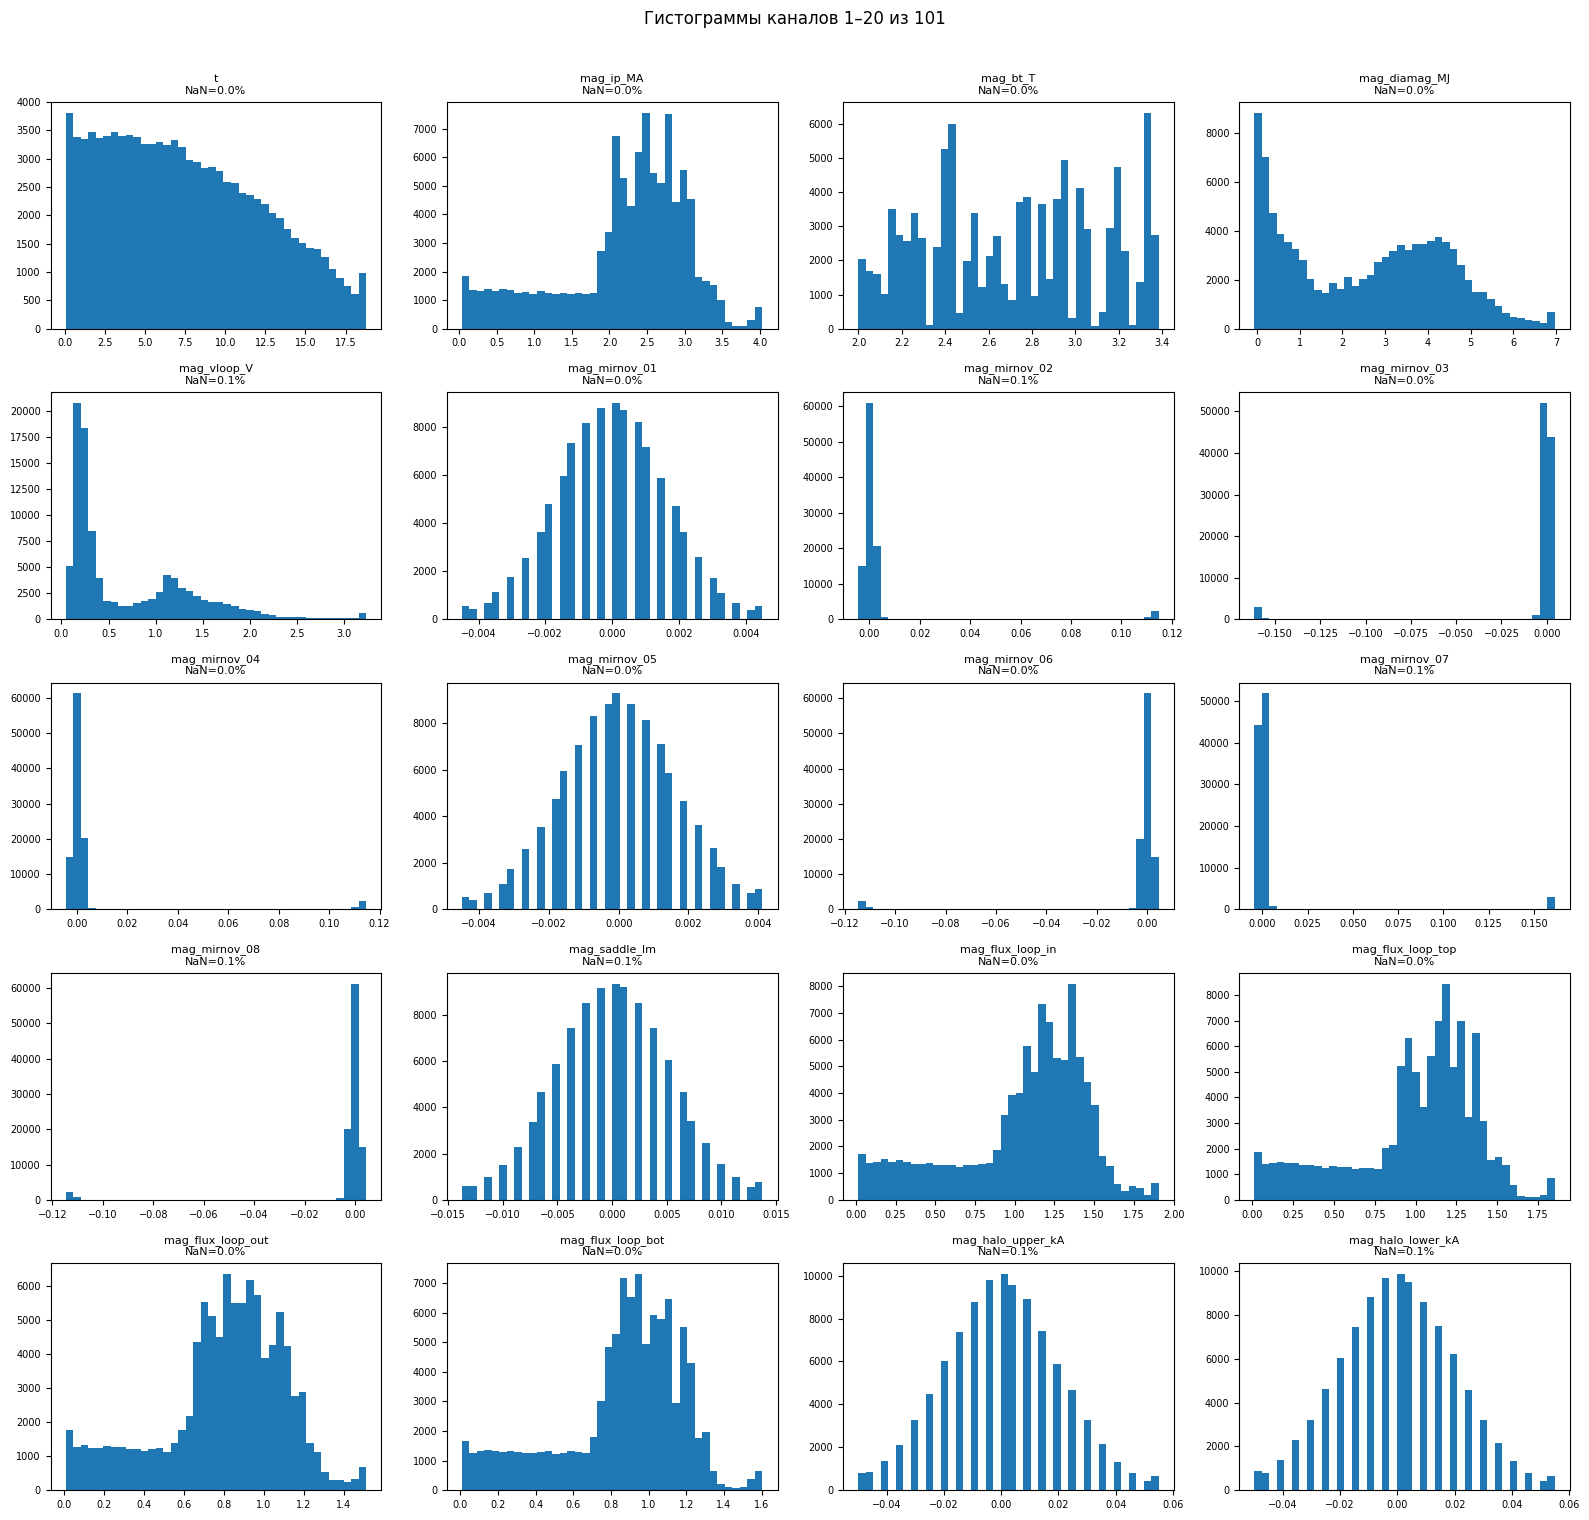

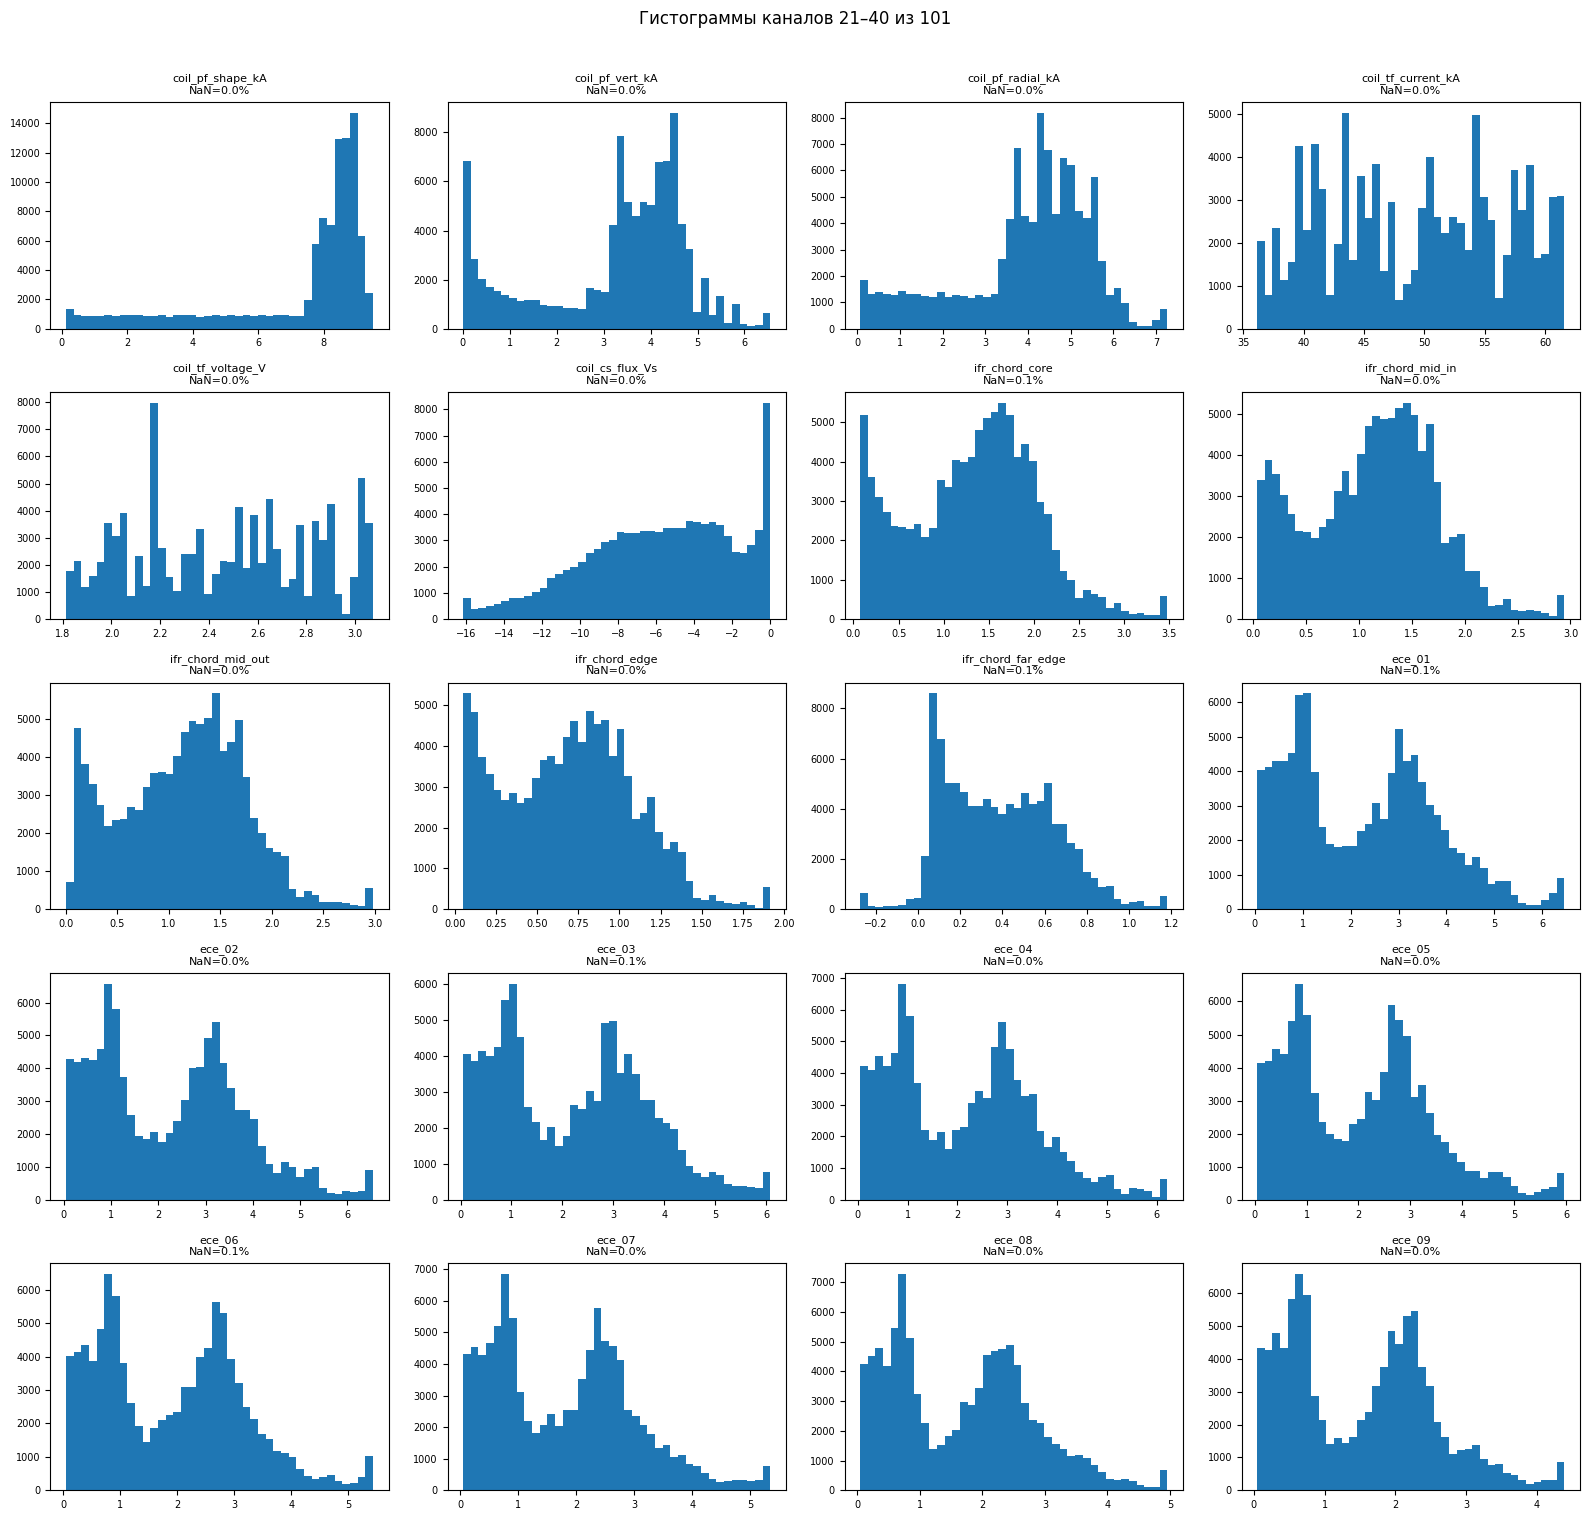

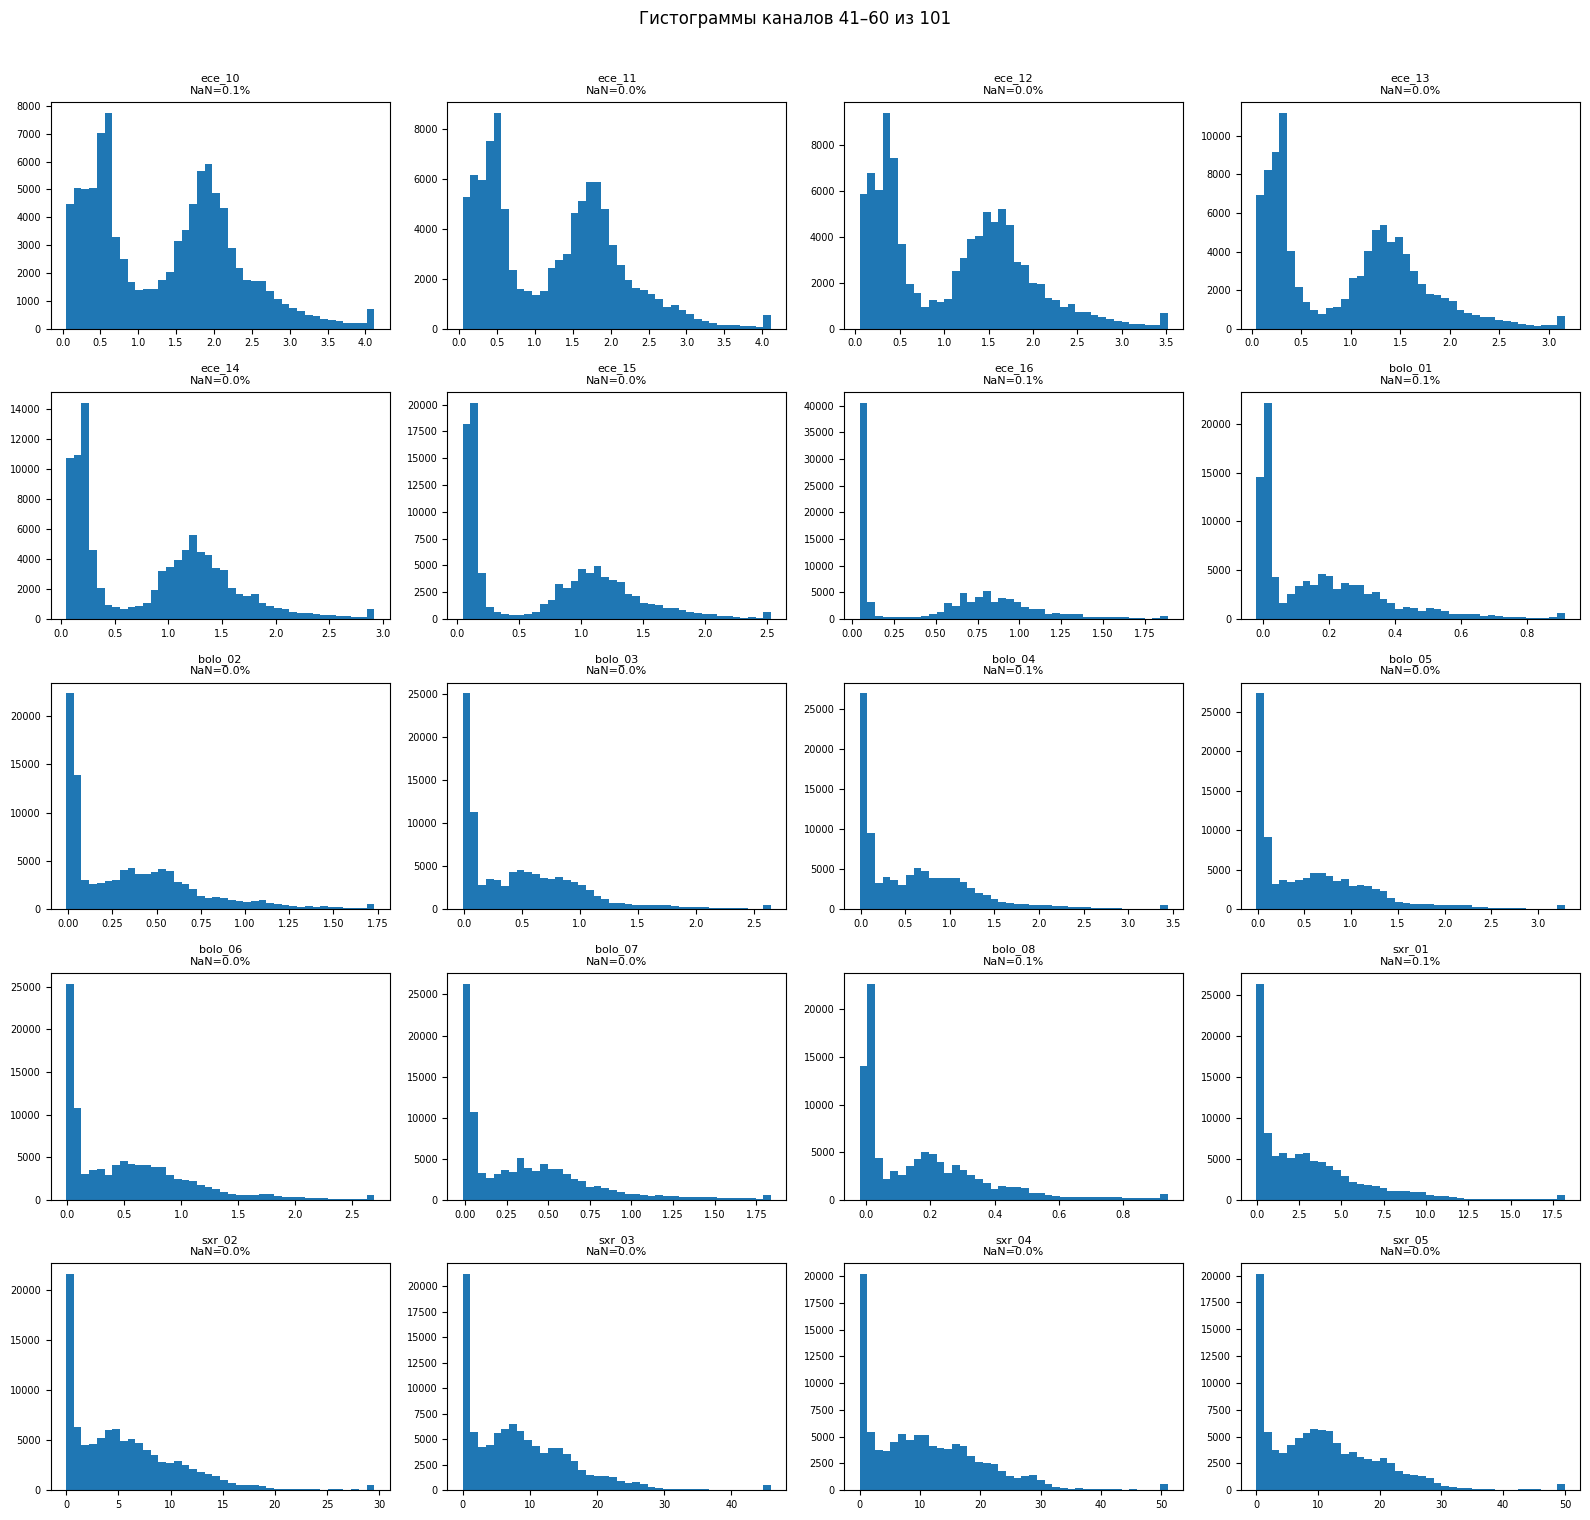

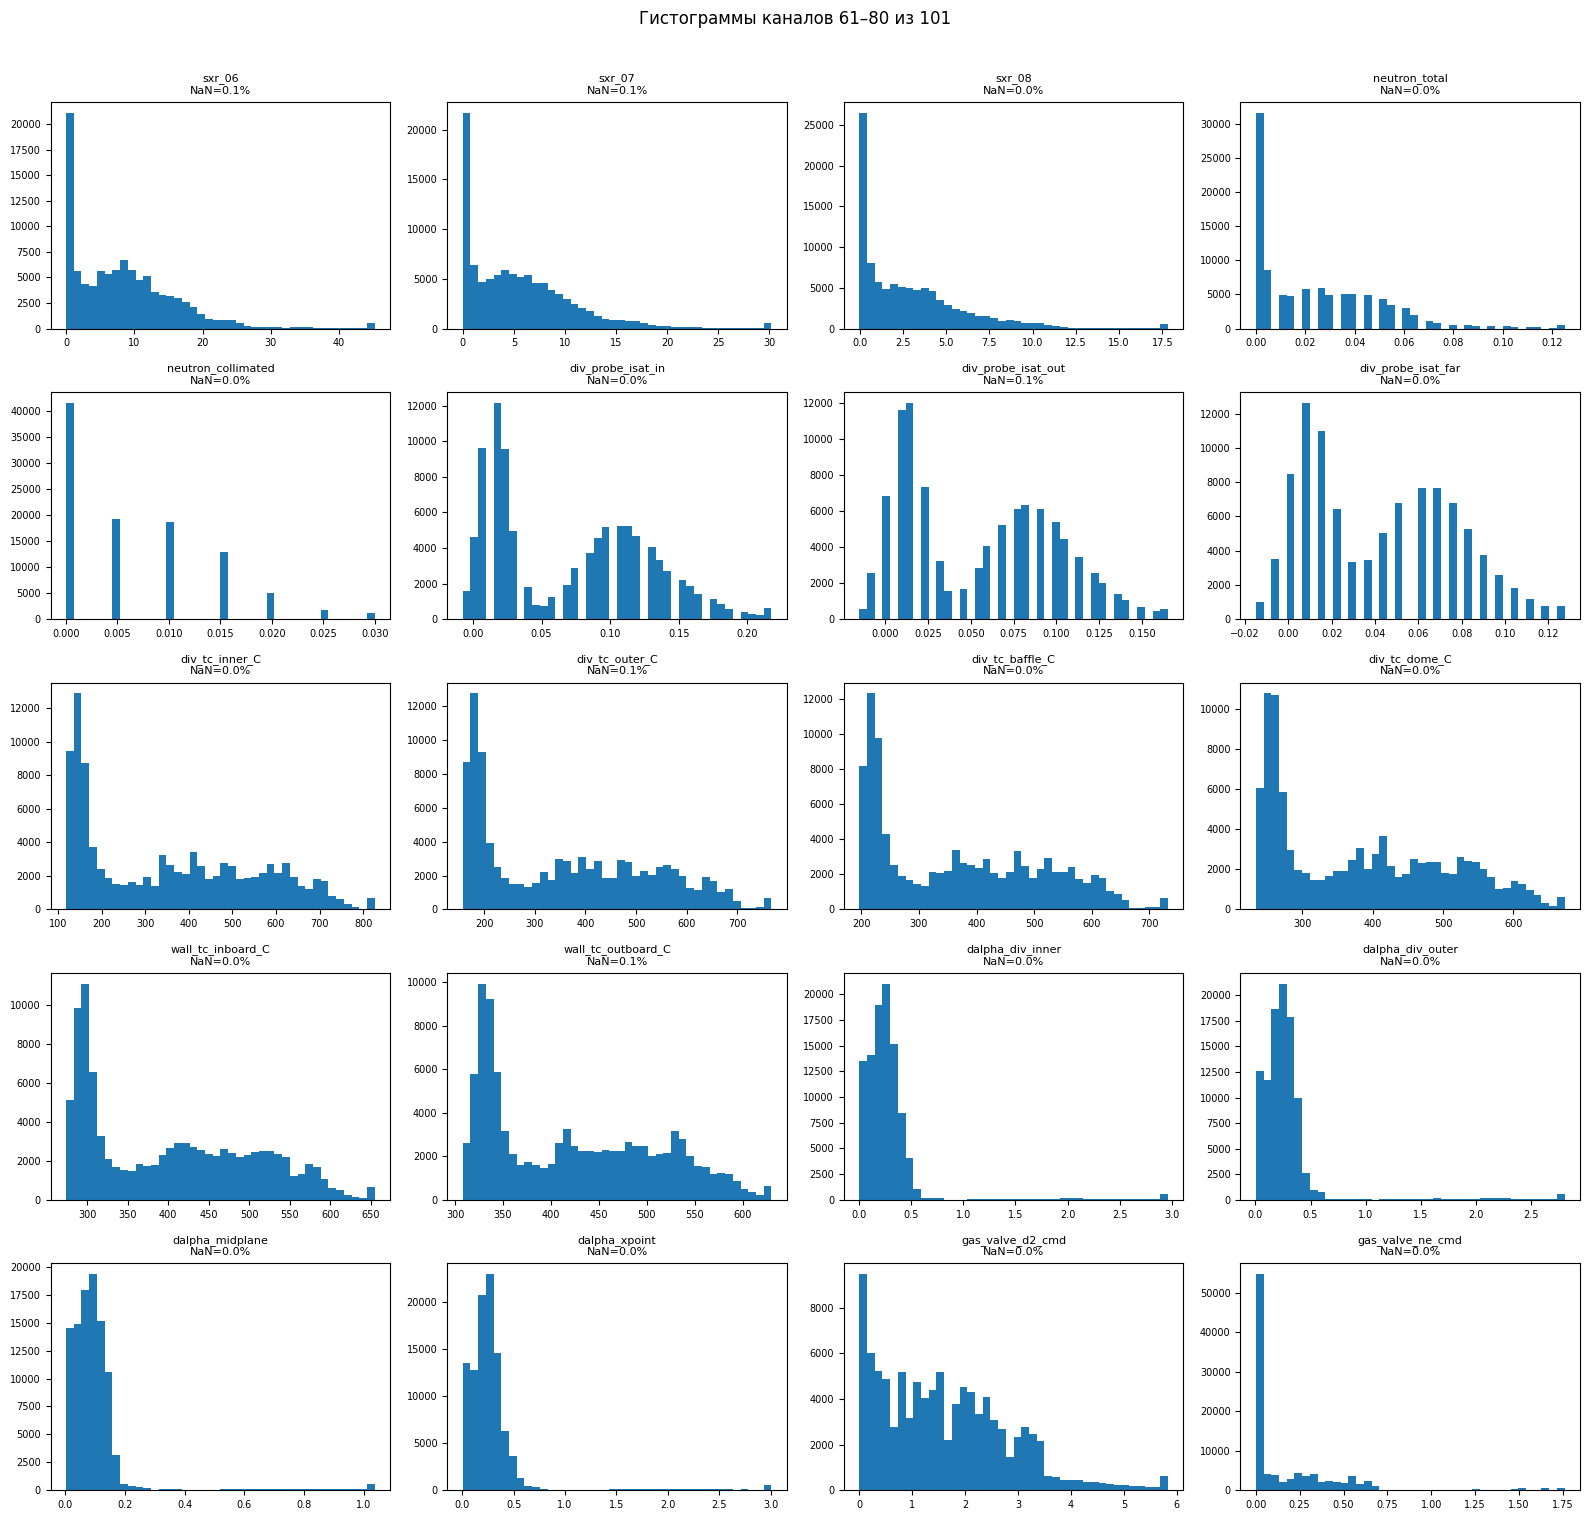

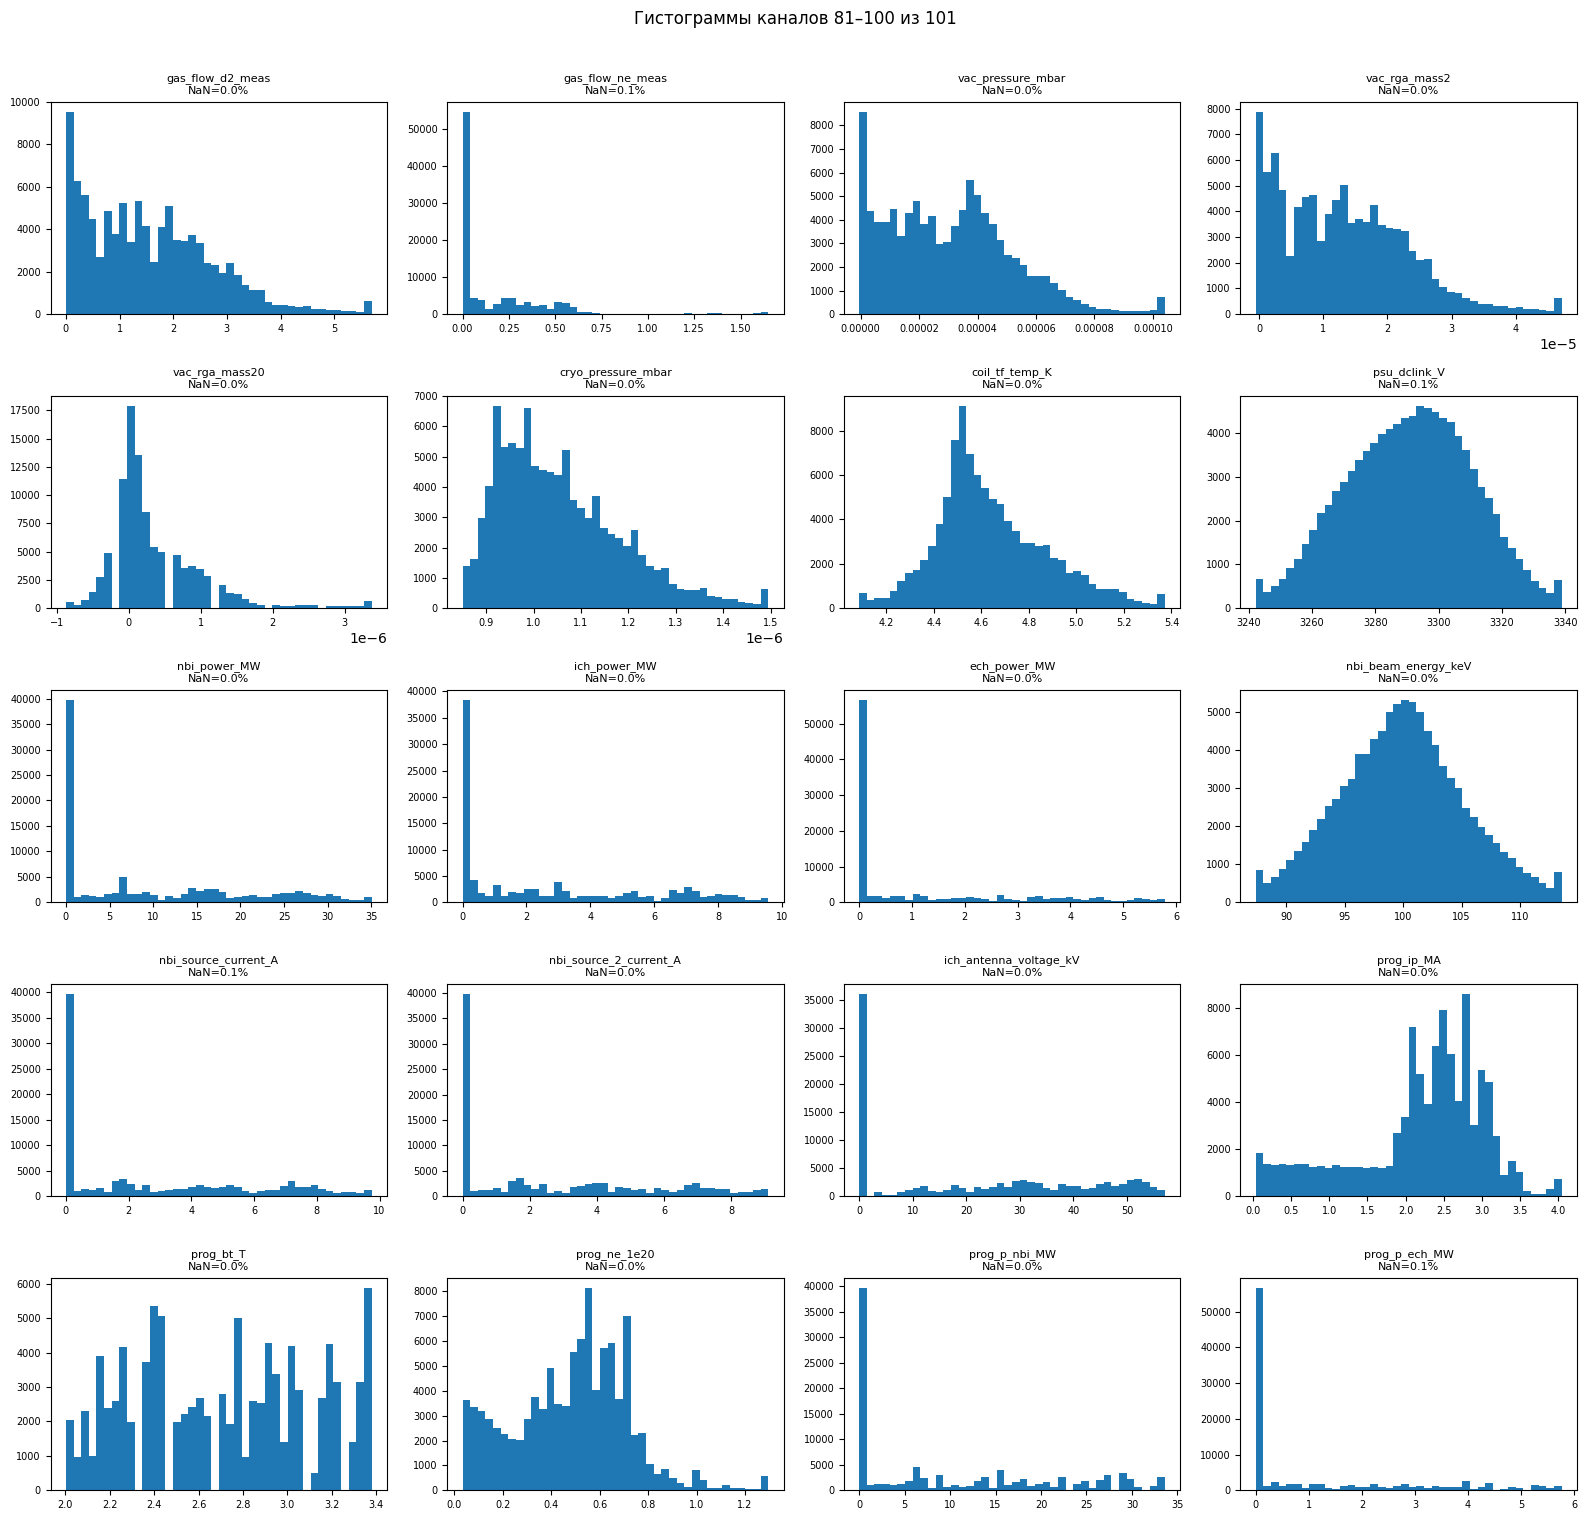

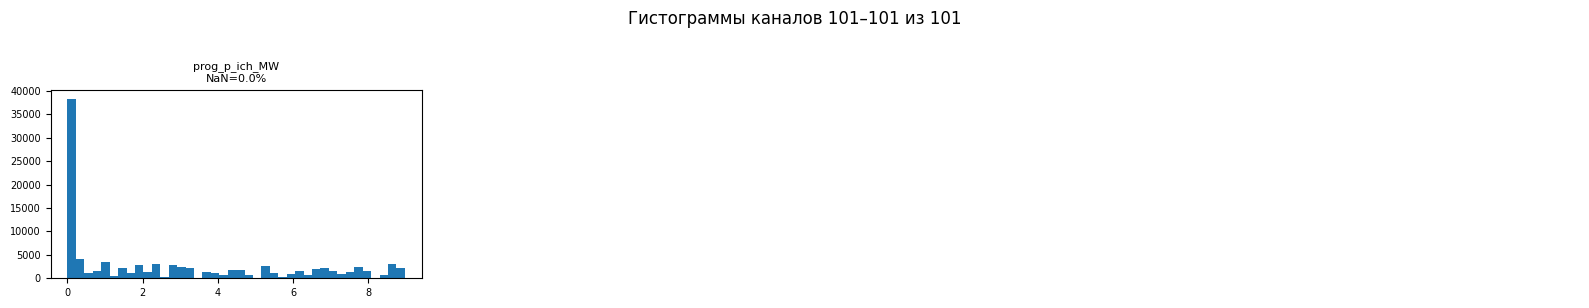

In [12]:
import math
import matplotlib.pyplot as plt

EDA_MAX_ROWS = 100_000
eda_numeric = measured.drop(columns=["shot_id"], errors="ignore").select_dtypes(include=[np.number])
if len(eda_numeric) > EDA_MAX_ROWS:
    rng = np.random.default_rng(RANDOM_STATE)
    chosen = np.sort(rng.choice(len(eda_numeric), size=EDA_MAX_ROWS, replace=False))
    eda_sample = eda_numeric.iloc[chosen].copy()
else:
    eda_sample = eda_numeric.copy()

eda_profile = pd.DataFrame({
    "missing_pct": (eda_numeric.isna().mean() * 100).round(3),
    "n_unique": eda_numeric.nunique(dropna=True),
    "sample_min": eda_sample.min(skipna=True),
    "sample_p01": eda_sample.quantile(0.01),
    "sample_median": eda_sample.median(skipna=True),
    "sample_p99": eda_sample.quantile(0.99),
    "sample_max": eda_sample.max(skipna=True),
})
eda_profile["near_constant"] = eda_profile["n_unique"] <= 2
print(f"Для гистограмм использовано строк: {len(eda_sample):,} из {len(eda_numeric):,}")
print("Каналы с наибольшим количеством пропусков:")
display(eda_profile.sort_values("missing_pct", ascending=False).head(25))
print("Почти постоянные/постоянные каналы:")
display(eda_profile.loc[eda_profile["near_constant"]].sort_values("n_unique"))

eda_columns = list(eda_numeric.columns)
BATCH_SIZE = 20
for start in range(0, len(eda_columns), BATCH_SIZE):
    batch = eda_columns[start:start + BATCH_SIZE]
    ncols = 4
    nrows = math.ceil(len(batch) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.0 * nrows))
    axes = np.asarray(axes).reshape(-1)
    for ax, col in zip(axes, batch):
        values = eda_sample[col].replace([np.inf, -np.inf], np.nan).dropna()
        if values.empty:
            ax.set_title(f"{col}\nнет чисел", fontsize=8)
            ax.axis("off")
            continue
    
        lo, hi = values.quantile([0.005, 0.995])
        shown = values.clip(lower=lo, upper=hi) if lo < hi else values
        ax.hist(shown, bins=40)
        ax.set_title(f"{col}\nNaN={eda_profile.loc[col, 'missing_pct']:.1f}%", fontsize=8)
        ax.tick_params(axis="both", labelsize=7)
    for ax in axes[len(batch):]:
        ax.axis("off")
    fig.suptitle(f"Гистограммы каналов {start + 1}–{start + len(batch)} из {len(eda_columns)}", y=1.01)
    fig.tight_layout()
    plt.show()


## 2. Подготовка таргета

Для зривного разряда метка равна 1, если `0 < t_tq_s - t <= LEAD_TIME_S`; раньше этого окна и для безопасных разрядов метка равна 0. Строки при `t >= t_tq_s` исключаются, поскольку это уже не прогноз до гашения.

Разряды со срывом, помеченным как `spontaneous` или `wall_contact`, а также зривные разряды без `t_tq_s`, исключаются из обучения и оценки: методичка относит их к `Excluded`. Безопасные разряды сохраняются.

In [13]:
def as_bool(series: pd.Series) -> pd.Series:
    """Надёжно переводит CSV-значения true/false в bool."""
    return series.astype(str).str.strip().str.lower().isin({"true", "1", "yes", "y", "t"})

shots = shots.copy()
shots["disrupted_bool"] = as_bool(shots["disrupted"])
if "spontaneous" in shots:
    shots["spontaneous_bool"] = as_bool(shots["spontaneous"])
else:
    shots["spontaneous_bool"] = False
if "wall_contact" in shots:
    shots["wall_contact_bool"] = as_bool(shots["wall_contact"])
else:
    shots["wall_contact_bool"] = False

bad_disruption = (
    shots["disrupted_bool"]
    & (
        shots["spontaneous_bool"]
        | shots["wall_contact_bool"]
        | shots["t_tq_s"].isna()
    )
)
excluded_shot_ids = set(shots.loc[bad_disruption, "shot_id"])
shots_eligible = shots.loc[~bad_disruption].copy()

meta_cols = [
    "shot_id", "disrupted_bool", "t_tq_s",
    "spontaneous_bool", "wall_contact_bool",
]
df = measured.merge(
    shots_eligible[meta_cols],
    on="shot_id",
    how="inner",
    validate="many_to_one",
)
df = df.sort_values(["shot_id", "t"]).reset_index(drop=True)

post_quench = df["disrupted_bool"] & (df["t"] >= df["t_tq_s"])
df = df.loc[~post_quench].copy().reset_index(drop=True)

time_to_tq = df["t_tq_s"] - df["t"]
df["target_y"] = (
    df["disrupted_bool"]
    & (time_to_tq > 0)
    & (time_to_tq <= LEAD_TIME_S)
).astype("int8")

y = df["target_y"].astype("int8")
shot_info = shots_eligible[meta_cols].drop_duplicates("shot_id").copy()
print(f"Исключено непригодных зривных разрядов: {len(excluded_shot_ids)}")
print(f"Оставлено разрядов: {shot_info['shot_id'].nunique()}")
print(f"Строк после удаления данных t >= t_Q: {len(df):,}")
print(f"Положительных строк: {int(y.sum()):,} ({y.mean():.4%})")
print("Исходы разрядов:")
display(shot_info["disrupted_bool"].value_counts().rename(index={False: "без срыва", True: "допустимый срыв"}).to_frame("shots"))

if y.sum() == 0:
    raise ValueError(
        "Таргет не содержит положительных строк. Проверь t_tq_s и LEAD_TIME_S; не заменяй t_tq_s на t_trigger_s автоматически."
    )
if shot_info["disrupted_bool"].nunique() < 2:
    raise ValueError("Нужны как безопасные, так и зривные разряды для сравнения модели.")

Исключено непригодных зривных разрядов: 4
Оставлено разрядов: 96
Строк после удаления данных t >= t_Q: 271,681
Положительных строк: 1,963 (0.7225%)
Исходы разрядов:


,shots
disrupted_bool,
без срыва,63
допустимый срыв,33


## 3. Четыре варианта признаков

- **Raw:** исходные измеряемые числовые каналы и время; `shot_id` исключается из X. Базовая очистка — типы, удаление accidental index columns, бесконечности как пропуски. Нет ручного масштабирования/биннинга.
- **Physics:** агрегаты групп датчиков, относительный контраст каналов, амплитуды диагностик и ошибки между измерениями и заданными программами, а также измерительный прокси V_loop / I_p из описанной в основном тексте связи V_loop = I_p R_plasma. Он не применяет формулу Спитцера из шпаргалки. Признаки мотивированы описанием диагностик в методичке, но не вычисляют `q95`, `f_GW`, `beta_N`, `tau_E`, `P_rad/P_in` и другие величины из шпаргалки.
- **Dynamics:** Physics + лаги, разности, наклоны и скользящие агрегаты по прошлым и текущему времени в том же `shot_id`. Без `bfill` и без будущих строк.
- **FormulaSheetProxies (analysis only):** дополнительная группа приближённых соотношений, вдохновлённых шпаргалкой. Эти прокси неточны и не должны идти в официальную модель, если использование формул шпаргалки запрещено.

Все четыре варианта проходят через тот же алгоритм, тот же grouped train/validation split и те же метрики. Сравнивайте ROC-AUC/PR-AUC вместе с Caught/False alarm: высокое качество ранжирования отдельных строк не гарантирует своевременную тревогу на уровне целого разряда.


In [14]:
def _row_agg(frame: pd.DataFrame, columns, how="mean") -> pd.Series:
    cols = [c for c in columns if c in frame.columns]
    if not cols:
        return pd.Series(np.nan, index=frame.index, dtype=float)
    values = frame[cols]
    if how == "mean":
        return values.mean(axis=1)
    if how == "max":
        return values.max(axis=1)
    if how == "min":
        return values.min(axis=1)
    if how == "std":
        return values.std(axis=1)
    if how == "rms":
        return np.sqrt((values ** 2).mean(axis=1))
    if how == "abs_sum":
        return values.abs().sum(axis=1, min_count=1)
    raise ValueError(f"Неизвестная агрегация: {how}")


def make_physics_features(raw: pd.DataFrame) -> pd.DataFrame:
    """Исходные измерения + физически мотивированные диагностические прокси.

    Важные оговорки:
    - это не восстановленные истинные состояния симулятора;
    - болометрические и интерферометрические агрегаты имеют смысл как прокси,
      пока не подтверждены точная калибровка и единицы измерения;
    - используются только каналы measured.csv, доступные модели на текущем шаге.
    """
    out = raw.copy()
    eps = 1e-6


    heating_cols = [c for c in ["nbi_power_MW", "ich_power_MW", "ech_power_MW"] if c in out.columns]
    if heating_cols:
        out["feat_input_power_MW"] = out[heating_cols].clip(lower=0).sum(axis=1, min_count=1)


    chord_cols = [c for c in out.columns if c.startswith("ifr_chord_")]
    if chord_cols:
        out["feat_chord_mean"] = _row_agg(out, chord_cols, "mean")
        out["feat_chord_spread"] = _row_agg(out, chord_cols, "max") - _row_agg(out, chord_cols, "min")
        if {"ifr_chord_core", "ifr_chord_edge", "ifr_chord_far_edge"}.issubset(out.columns):
            edge_proxy = (out["ifr_chord_edge"].abs() + out["ifr_chord_far_edge"].abs()) / 2
            out["feat_ifr_edge_core_ratio_proxy"] = edge_proxy / (out["ifr_chord_core"].abs() + 0.01)


    mirnov_cols = [c for c in out.columns if c.startswith("mag_mirnov_")]
    if mirnov_cols:
        out["feat_mirnov_rms"] = _row_agg(out, mirnov_cols, "rms")


    dalpha_cols = [c for c in out.columns if c.startswith("dalpha_")]
    if dalpha_cols:
        out["feat_dalpha_mean_abs"] = out[dalpha_cols].abs().mean(axis=1)
        out["feat_dalpha_max_abs"] = out[dalpha_cols].abs().max(axis=1)
        out["feat_dalpha_peak_ratio_proxy"] = out["feat_dalpha_max_abs"] / (out["feat_dalpha_mean_abs"] + 1e-4)



    ece_cols = sorted([c for c in out.columns if c.startswith("ece_")])
    if ece_cols:
        out["feat_ece_mean"] = _row_agg(out, ece_cols, "mean")
        out["feat_ece_spread"] = _row_agg(out, ece_cols, "max") - _row_agg(out, ece_cols, "min")
        if len(ece_cols) >= 4:
            mid = len(ece_cols) // 2
            first_half_mean = out[ece_cols[:mid]].mean(axis=1)
            second_half_mean = out[ece_cols[mid:]].mean(axis=1)
            out["feat_ece_half_contrast"] = second_half_mean - first_half_mean



    bolo_cols = [c for c in out.columns if c.startswith("bolo_")]
    if bolo_cols:
        abs_bolo = out[bolo_cols].abs()
        out["feat_bolo_abs_sum"] = abs_bolo.sum(axis=1, min_count=1)
        out["feat_bolo_max_abs"] = abs_bolo.max(axis=1)
        out["feat_bolo_concentration_proxy"] = out["feat_bolo_max_abs"] / (out["feat_bolo_abs_sum"] + 1e-6)


    sxr_cols = [c for c in out.columns if c.startswith("sxr_")]
    if sxr_cols:
        abs_sxr = out[sxr_cols].abs()
        out["feat_sxr_abs_sum"] = abs_sxr.sum(axis=1, min_count=1)
        out["feat_sxr_max_abs"] = abs_sxr.max(axis=1)



    if {"mag_vloop_V", "mag_ip_MA"}.issubset(out.columns):
        out["feat_vloop_per_current_proxy"] = (
            out["mag_vloop_V"].abs() / (out["mag_ip_MA"].abs() + 0.03)
        )
    if "mag_saddle_lm" in out.columns:
        out["feat_locked_mode_abs"] = out["mag_saddle_lm"].abs()
    if "neutron_total" in out.columns:
        out["feat_neutron_log1p"] = np.log1p(out["neutron_total"].clip(lower=0))

    if {"mag_ip_MA", "prog_ip_MA"}.issubset(out.columns):
        out["feat_ip_tracking_error"] = out["mag_ip_MA"] - out["prog_ip_MA"]
    if {"mag_bt_T", "prog_bt_T"}.issubset(out.columns):
        out["feat_bt_tracking_error"] = out["mag_bt_T"] - out["prog_bt_T"]
    prog_heating_cols = [c for c in ["prog_p_nbi_MW", "prog_p_ech_MW", "prog_p_ich_MW"] if c in out.columns]
    if prog_heating_cols and "feat_input_power_MW" in out.columns:
        out["feat_heating_tracking_error"] = out["feat_input_power_MW"] - out[prog_heating_cols].clip(lower=0).sum(axis=1, min_count=1)

    if {"gas_flow_ne_meas", "gas_flow_d2_meas"}.issubset(out.columns):
        out["feat_neon_to_d2_flow_proxy"] = out["gas_flow_ne_meas"].abs() / (out["gas_flow_d2_meas"].abs() + 1e-8)


    pf_cols = [c for c in ["coil_pf_shape_kA", "coil_pf_vert_kA", "coil_pf_radial_kA"] if c in out.columns]
    if pf_cols:
        out["feat_pf_coil_abs_sum"] = out[pf_cols].abs().sum(axis=1, min_count=1)
    if {"coil_pf_vert_kA", "coil_pf_radial_kA"}.issubset(out.columns):
        out["feat_pf_radial_minus_vert"] = out["coil_pf_radial_kA"] - out["coil_pf_vert_kA"]

    return out.replace([np.inf, -np.inf], np.nan)



def make_formula_sheet_proxy_features(raw: pd.DataFrame) -> pd.DataFrame:
    """Research-only ablation: Physics plus approximate proxies inspired by the formula sheet.

    This feature family is for measuring the effect of those proxies on offline metrics only.
    Do not export it as the hackathon submission if use of formula-sheet equations is forbidden.
    These are not exact reconstructed physical state variables.
    """
    out = make_physics_features(raw)
    eps_ip = 0.03


    if {"mag_bt_T", "mag_ip_MA"}.issubset(out.columns):
        out["feat_q95_base_proxy"] = (
            5.0 * (0.95 ** 2) * out["mag_bt_T"].abs()
            / (2.89 * (out["mag_ip_MA"].abs() + eps_ip))
        )
        out["feat_ip_over_bt"] = out["mag_ip_MA"].abs() / (out["mag_bt_T"].abs() + 0.05)


    if {"feat_chord_mean", "mag_ip_MA"}.issubset(out.columns):
        out["feat_chord_per_current_proxy"] = (
            out["feat_chord_mean"].abs() / (out["mag_ip_MA"].abs() + eps_ip)
        )



    if {"feat_input_power_MW", "mag_diamag_MJ"}.issubset(out.columns):
        out["feat_heating_to_energy_s_inv_proxy"] = (
            out["feat_input_power_MW"] / (out["mag_diamag_MJ"].abs() + 0.02)
        )
    if {"feat_bolo_abs_sum", "feat_input_power_MW"}.issubset(out.columns):
        out["feat_bolo_to_heating_proxy"] = (
            out["feat_bolo_abs_sum"] / out["feat_input_power_MW"].abs().clip(lower=0.5)
        )

    return out.replace([np.inf, -np.inf], np.nan)


def make_dynamic_features(raw: pd.DataFrame) -> pd.DataFrame:
    """Physics-признаки + лаги, тренды и скользящие статистики только по прошлому/текущему."""
    out = make_physics_features(raw)
    if "shot_id" not in out.columns:
        raise ValueError("Для динамических признаков нужен shot_id, чтобы не смешивать разряды.")
    out = out.sort_values(["shot_id", "t"]).copy()
    dyn = {} 


    lag_sources = [
        "mag_ip_MA", "prog_ip_MA", "mag_saddle_lm", "mag_diamag_MJ",
        "mag_vloop_V", "ifr_chord_core", "neutron_total", "feat_dalpha_max_abs",
        "feat_mirnov_rms", "feat_input_power_MW", "feat_bolo_abs_sum", "feat_sxr_abs_sum",
    ]
    for col in [c for c in lag_sources if c in out.columns]:
        grouped = out.groupby("shot_id", sort=False)[col]
        for lag in (1, 3, 10, 20):
            dyn[f"dyn__{col}__lag{lag}"] = grouped.shift(lag)



    delta_sources = [
        "mag_ip_MA", "prog_ip_MA", "mag_saddle_lm", "mag_diamag_MJ",
        "neutron_total", "feat_dalpha_max_abs", "feat_mirnov_rms",
        "feat_bolo_abs_sum", "feat_input_power_MW",
    ]
    grouped_t = out.groupby("shot_id", sort=False)["t"]
    for col in [c for c in delta_sources if c in out.columns]:
        grouped = out.groupby("shot_id", sort=False)[col]
        for lag in (10, 50):
            past = grouped.shift(lag)
            delta = out[col] - past
            dyn[f"dyn__{col}__delta{lag}"] = delta
            if col in {"mag_ip_MA", "prog_ip_MA", "mag_saddle_lm", "feat_bolo_abs_sum", "feat_input_power_MW"}:
                elapsed = out["t"] - grouped_t.shift(lag)
                dyn[f"dyn__{col}__slope{lag}"] = delta / elapsed.where(elapsed > 0)


    rolling_sources = [
        "mag_ip_MA", "mag_saddle_lm", "mag_diamag_MJ", "neutron_total",
        "feat_dalpha_max_abs", "feat_dalpha_peak_ratio_proxy", "feat_mirnov_rms",
        "feat_bolo_abs_sum", "feat_input_power_MW",
    ]
    for col in [c for c in rolling_sources if c in out.columns]:
        grouped = out.groupby("shot_id", sort=False)[col]
        for window in (10, 50):
            dyn[f"dyn__{col}__mean{window}"] = grouped.transform(
                lambda s, w=window: s.rolling(window=w, min_periods=1).mean()
            )
            dyn[f"dyn__{col}__std{window}"] = grouped.transform(
                lambda s, w=window: s.rolling(window=w, min_periods=2).std()
            )
            if col in {"mag_saddle_lm", "feat_dalpha_max_abs", "feat_bolo_abs_sum", "feat_sxr_abs_sum"}:
                dyn[f"dyn__{col}__max{window}"] = grouped.transform(
                    lambda s, w=window: s.rolling(window=w, min_periods=1).max()
                )



    if "feat_dalpha_peak_ratio_proxy" in out.columns:
        high = (out["feat_dalpha_peak_ratio_proxy"] > 2.0).astype(float)
        dyn["dyn__dalpha_high_steps_100"] = high.groupby(out["shot_id"], sort=False).transform(
            lambda s: s.rolling(window=100, min_periods=1).sum()
        )

    dynamic_frame = pd.DataFrame(dyn, index=out.index)
    out = pd.concat([out, dynamic_frame], axis=1)
    return out.replace([np.inf, -np.inf], np.nan)

def model_matrix(feature_frame: pd.DataFrame) -> pd.DataFrame:
    """Удаляет идентификатор разряда, оставляет только числовые входные признаки."""
    X = feature_frame.drop(columns=["shot_id"], errors="ignore").copy()
    X = X.select_dtypes(include=[np.number])
    X = X.replace([np.inf, -np.inf], np.nan)

    return X.astype(np.float32)

raw_inputs = df[measured.columns].copy()
raw_inputs = raw_inputs.sort_values(["shot_id", "t"]).reset_index(drop=True)

feature_sets = {
    "Raw": model_matrix(raw_inputs),
    "Physics": model_matrix(make_physics_features(raw_inputs)),
    "Dynamics": model_matrix(make_dynamic_features(raw_inputs)),
    "FormulaSheetProxies": model_matrix(make_formula_sheet_proxy_features(raw_inputs)),
}

y = df["target_y"].astype("int8").reset_index(drop=True)
shot_ids = df["shot_id"].reset_index(drop=True)
for name, X in feature_sets.items():
    if len(X) != len(y):
        raise AssertionError(f"Несовпадение строк для {name}: X={len(X)}, y={len(y)}")
    print(f"{name:10s}: {X.shape[0]:,} строк × {X.shape[1]} признаков")

Raw       : 271,681 строк × 101 признаков
Physics   : 271,681 строк × 126 признаков
Dynamics  : 271,681 строк × 245 признаков
FormulaSheetProxies: 271,681 строк × 131 признаков


## 4. Разбиение по разрядам и обучение

Разделяем **список разрядов**, а не временные строки: все строки одного `shot_id` целиком принадлежат либо train, либо validation. Используем один и тот же разрез и один тип классификатора для всех трёх наборов признаков.

Из-за редких положительных строк немного усиливаем их вес. Это помогает обучению, но сырые выходы модели не следует считать идеально откалиброванными вероятностями; для хакатона дополнительно выбирается рабочая точка по ложным тревогам на разрядах.

**Важно про гиперпараметры:** параметры XGBoost ниже заданы вручную как регуляризованный baseline. Они не являются победителем поиска из 800/1280 экспериментов. Сначала используй эти запуски, чтобы собрать shortlist конфигураций; окончательный выбор делай только через групповую проверку по `shot_id` и отдельные разряды/`Master seed`.

In [15]:

shot_summary = shot_info[["shot_id", "disrupted_bool"]].drop_duplicates("shot_id").copy()
class_counts = shot_summary["disrupted_bool"].value_counts()
if len(class_counts) < 2 or class_counts.min() < 2:
    raise ValueError(
        "Для группового holdout нужно минимум по два разряда каждого исхода. "
        "Сгенерируй больше разрядов в Dataset и повтори запуск."
    )

train_ids, valid_ids = train_test_split(
    shot_summary["shot_id"].to_numpy(),
    test_size=VALID_SIZE,
    random_state=RANDOM_STATE,
    stratify=shot_summary["disrupted_bool"].astype(int).to_numpy(),
)
train_ids, valid_ids = set(train_ids), set(valid_ids)
train_mask = shot_ids.isin(train_ids).to_numpy()
valid_mask = shot_ids.isin(valid_ids).to_numpy()

print(f"Train: {len(train_ids)} разрядов, {int(train_mask.sum()):,} строк")
print(f"Validation: {len(valid_ids)} разрядов, {int(valid_mask.sum()):,} строк")
print("Срывы в train/validation:",
      int(shot_summary[shot_summary.shot_id.isin(train_ids)].disrupted_bool.sum()), "/",
      int(shot_summary[shot_summary.shot_id.isin(valid_ids)].disrupted_bool.sum()))


def positive_class_weight(y_train: pd.Series) -> float:
    counts = np.bincount(np.asarray(y_train, dtype=int), minlength=2)
    if counts[1] == 0:
        raise ValueError(
            "В train нет положительных строк. Нужен больший датасет/другая групповая выборка."
        )

    return float(np.clip(np.sqrt(counts[0] / counts[1]), 1.0, 20.0))


def make_classifier(pos_weight: float):
    if HAS_XGBOOST:
        return XGBClassifier(
            n_estimators=350,
            max_depth=4,
            learning_rate=0.035,
            min_child_weight=5,
            subsample=0.85,
            colsample_bytree=0.80,
            gamma=0.10,
            reg_alpha=0.2,
            reg_lambda=5.0,
            scale_pos_weight=pos_weight,
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            n_jobs=N_JOBS,
            random_state=RANDOM_STATE,
        )
    return HistGradientBoostingClassifier(
        max_iter=250,
        learning_rate=0.06,
        max_leaf_nodes=15,
        l2_regularization=2.0,
        random_state=RANDOM_STATE,
    )


def fit_classifier(X_train: pd.DataFrame, y_train: pd.Series):
    weight = positive_class_weight(y_train)
    model = make_classifier(weight)
    if HAS_XGBOOST:
        model.fit(X_train, y_train)
    else:
        sample_weight = np.where(np.asarray(y_train) == 1, weight, 1.0)
        model.fit(X_train, y_train, sample_weight=sample_weight)
    return model


def get_probabilities(model, X: pd.DataFrame) -> np.ndarray:
    p = np.asarray(model.predict_proba(X)[:, 1], dtype=float)
    return np.clip(np.nan_to_num(p, nan=0.0, posinf=1.0, neginf=0.0), 0.0, 1.0)


def row_ranking_metrics(y_true, p) -> dict:
    y_true = np.asarray(y_true, dtype=int)
    if len(np.unique(y_true)) < 2:
        return {"roc_auc": np.nan, "pr_auc": np.nan}
    return {
        "roc_auc": float(roc_auc_score(y_true, p)),
        "pr_auc": float(average_precision_score(y_true, p)),
    }

Train: 72 разрядов, 206,294 строк
Validation: 24 разрядов, 65,387 строк
Срывы в train/validation: 25 / 8


## 5. Оценка тревоги на уровне разряда

Для каждого разряда тревога возникает при первом `p >= threshold`. `Caught` означает, что первая тревога появилась минимум за `LEAD_TIME_S` до `t_tq_s`. На безопасном разряде любая тревога — ложная.

Порог подбирается на validation так, чтобы доля ложных тревог не превысила `FALSE_ALARM_BUDGET`, а доля `Caught` была максимальной. Это **выбор рабочей точки**, поэтому его результат оптимистичен на этой же validation-выборке. Для финального обоснования повтори проверку на другом `Master seed` и через настоящий `toksym Test run`.

In [16]:
def shot_level_metrics(scored_rows: pd.DataFrame, validation_shots: pd.DataFrame,
                       threshold: float, lead_time_s: float) -> dict:
    alarms = (
        scored_rows.loc[scored_rows["p"] >= threshold]
        .groupby("shot_id")["t"].min()
    )
    safe_shots = validation_shots.loc[~validation_shots["disrupted_bool"]]
    event_shots = validation_shots.loc[validation_shots["disrupted_bool"]]

    false_alarms = int(sum(sid in alarms.index for sid in safe_shots["shot_id"]))
    n_safe = int(len(safe_shots))

    caught = 0
    late = 0
    missed = 0
    for row in event_shots.itertuples(index=False):
        alarm_t = alarms.get(row.shot_id, np.nan)
        if pd.isna(alarm_t):
            missed += 1
        elif (row.t_tq_s - alarm_t) >= lead_time_s:
            caught += 1
        else:
            late += 1

    n_events = int(len(event_shots))
    return {
        "threshold": float(threshold),
        "caught": caught,
        "n_events": n_events,
        "caught_rate": caught / n_events if n_events else np.nan,
        "late": late,
        "missed": missed,
        "false_alarms": false_alarms,
        "n_safe": n_safe,
        "false_alarm_rate": false_alarms / n_safe if n_safe else np.nan,
    }


def choose_threshold(scored_rows: pd.DataFrame, validation_shots: pd.DataFrame,
                     lead_time_s: float, false_alarm_budget: float):
    """Подбирает порог по максимумам безопасных разрядов и ранним максимумам срывных."""
    per_shot_max = scored_rows.groupby("shot_id")["p"].max()
    safe_ids = set(validation_shots.loc[~validation_shots["disrupted_bool"], "shot_id"])
    safe_max = per_shot_max.reindex(list(safe_ids)).dropna().to_numpy()
    if len(safe_max) == 0:
        raise ValueError("В validation нет безопасных разрядов — нельзя выставить бюджет ложных тревог.")

    early_rows = scored_rows.loc[
        scored_rows["disrupted_bool"]
        & scored_rows["t_tq_s"].notna()
        & (scored_rows["t"] <= scored_rows["t_tq_s"] - lead_time_s)
    ]
    early_max = early_rows.groupby("shot_id")["p"].max().dropna().to_numpy()

    raw_candidates = np.concatenate([safe_max, early_max])
    candidates = np.unique(np.concatenate([
        raw_candidates,
        np.nextafter(raw_candidates, np.inf),
    ]))
    candidates = candidates[np.isfinite(candidates)]
    candidates = np.clip(candidates, 0.0, 1.0)

    validation_shots = validation_shots.copy()
    options = []
    for threshold in candidates:
        m = shot_level_metrics(scored_rows, validation_shots, float(threshold), lead_time_s)
        if np.isfinite(m["false_alarm_rate"]) and m["false_alarm_rate"] <= false_alarm_budget + 1e-12:
    
            options.append((m["caught_rate"], -m["false_alarm_rate"], float(threshold), m))

    if not options:
        raise RuntimeError("Не найден порог в заданном бюджете ложных тревог.")
    options.sort(key=lambda item: (item[0], item[1], item[2]), reverse=True)
    best = options[0]
    return best[2], best[3]
validation_shots = shot_info.loc[shot_info["shot_id"].isin(valid_ids)].copy()
validation_rows = df.loc[valid_mask, [
    "shot_id", "t", "t_tq_s", "disrupted_bool", "target_y"
]].copy().reset_index(drop=True)

results = []
fitted_models = {}
validation_scores = {}
feature_columns_used = {}

for variant, full_X in feature_sets.items():
    print(f"Обучение варианта: {variant} ...")
    X_train = full_X.loc[train_mask].copy()
    X_valid = full_X.loc[valid_mask].copy()
    y_train = y.loc[train_mask].copy()
    y_valid = y.loc[valid_mask].copy()

    usable_cols = X_train.columns[X_train.notna().any(axis=0)].tolist()
    if not usable_cols:
        raise ValueError(f"У варианта {variant} нет непустых признаков в train.")
    X_train = X_train[usable_cols]
    X_valid = X_valid[usable_cols]

    model = fit_classifier(X_train, y_train)
    p_valid = get_probabilities(model, X_valid)
    ranking = row_ranking_metrics(y_valid, p_valid)

    scored = validation_rows.copy()
    scored["p"] = p_valid
    threshold, operating = choose_threshold(
        scored, validation_shots, LEAD_TIME_S, FALSE_ALARM_BUDGET
    )

    result = {
        "variant": variant,
        "n_features": len(usable_cols),
        **ranking,
        **operating,
    }
    results.append(result)
    fitted_models[variant] = model
    validation_scores[variant] = p_valid
    feature_columns_used[variant] = usable_cols

results_df = pd.DataFrame(results).sort_values(
    ["caught_rate", "pr_auc", "false_alarm_rate"],
    ascending=[False, False, True],
    na_position="last",
).reset_index(drop=True)
results_df["submission_eligible"] = results_df["variant"].isin({"Raw", "Physics", "Dynamics"})

print("\nСРАВНЕНИЕ НА ОДИНАКОВОЙ VALIDATION-ВЫБОРКЕ")
display(results_df[[
    "variant", "submission_eligible", "n_features", "roc_auc", "pr_auc", "threshold",
    "caught", "n_events", "caught_rate", "late", "missed",
    "false_alarms", "n_safe", "false_alarm_rate"
]].style.format({
    "roc_auc": "{:.4f}", "pr_auc": "{:.4f}", "threshold": "{:.5f}",
    "caught_rate": "{:.1%}", "false_alarm_rate": "{:.1%}"
}))

Обучение варианта: Raw ...
Обучение варианта: Physics ...
Обучение варианта: Dynamics ...
Обучение варианта: FormulaSheetProxies ...

СРАВНЕНИЕ НА ОДИНАКОВОЙ VALIDATION-ВЫБОРКЕ


,variant,submission_eligible,n_features,roc_auc,pr_auc,threshold,caught,n_events,caught_rate,late,missed,false_alarms,n_safe,false_alarm_rate
0,FormulaSheetProxies,False,131,0.9463,0.1732,0.95122,0,8,0.0%,2,6,0,16,0.0%
1,Physics,True,126,0.9446,0.1563,0.96657,0,8,0.0%,2,6,0,16,0.0%
2,Dynamics,True,245,0.9454,0.1308,0.95117,0,8,0.0%,2,6,0,16,0.0%
3,Raw,True,101,0.9429,0.0903,0.98104,0,8,0.0%,0,8,0,16,0.0%


## 6. Выбор модели и сохранение

Четыре варианта сравниваются на одинаковом наборе разрядов. Для официальной модели автоматически допускаются только **Raw, Physics и Dynamics**; `FormulaSheetProxies` — исследовательский контроль и не может попасть в экспортируемую модель.

Внутри разрешённых вариантов сначала максимизируем долю `Caught` при соблюдении `FALSE_ALARM_BUDGET`, затем используем PR-AUC как критерий разрешения равенства. ROC-AUC тоже сохраняется и полезен для сравнения ранжирования, но сам по себе не определяет своевременность тревоги.

Финальный `best_model.joblib` — лучший разрешённый вариант, переобученный на всех пригодных разрядах текущего набора. Это артефакт обучения, а не готовая папка TokSym: потоковый `model.py` должен точно воспроизводить признаки выбранного варианта. Для убедительного вывода необходима проверка на другом `Master seed`.


In [17]:
COMPLIANT_VARIANTS = {"Raw", "Physics", "Dynamics"}
results_df["submission_eligible"] = results_df["variant"].isin(COMPLIANT_VARIANTS)


compliant_results = results_df.loc[results_df["submission_eligible"]].reset_index(drop=True)
if compliant_results.empty:
    raise RuntimeError("Нет ни одного разрешённого варианта для сдачи.")

best_variant = str(compliant_results.iloc[0]["variant"])
best_threshold_validation = float(compliant_results.iloc[0]["threshold"])
best_model = fitted_models[best_variant]
best_columns = feature_columns_used[best_variant]

print("Выбранный разрешённый вариант для сохранения:", best_variant)
print(f"Caught на validation при бюджете {FALSE_ALARM_BUDGET:.1%}: "
      f"{compliant_results.iloc[0]['caught_rate']:.1%}")
print(f"Ложные тревоги на validation: {compliant_results.iloc[0]['false_alarm_rate']:.1%}")
print("FormulaSheetProxies остаётся только в сравнительной таблице и не экспортируется.")
print(f"Validation threshold (диагностический): {best_threshold_validation:.6f}")



X_all = feature_sets[best_variant][best_columns].copy()
y_all = y.copy()
final_model = fit_classifier(X_all, y_all)

bundle = {
    "model": final_model,
    "feature_variant": best_variant,
    "feature_columns": list(best_columns),
    "lead_time_s": float(LEAD_TIME_S),
    "false_alarm_budget": float(FALSE_ALARM_BUDGET),
    "validation_threshold_diagnostic_only": best_threshold_validation,
    "backend": MODEL_BACKEND,
    "random_state": RANDOM_STATE,
    "n_training_shots": int(shot_info["shot_id"].nunique()),
    "warning": (
        "Submission bundle uses only Raw/Physics/Dynamics. FormulaSheetProxies is analysis-only "
        "and excluded from export selection. Reproduce the selected features exactly in model.py "
        "and validate with a different Master seed."
    ),
}

try:
    import joblib
    joblib.dump(bundle, "best_model.joblib")
    print("\nСохранено: best_model.joblib")
except ImportError:
    print("joblib не установлен — модель обучена в памяти, но не сохранена.")

results_df.to_csv("model_comparison.csv", index=False)
print("Сохранено: model_comparison.csv")


if hasattr(final_model, "feature_importances_"):
    importances = pd.Series(final_model.feature_importances_, index=best_columns).sort_values(ascending=False)
    print("\nТоп-25 признаков:")
    display(importances.head(25).to_frame("importance"))
else:
    print("У выбранного backend нет готового атрибута feature_importances_.")

Выбранный разрешённый вариант для сохранения: Physics
Caught на validation при бюджете 5.0%: 0.0%
Ложные тревоги на validation: 0.0%
FormulaSheetProxies остаётся только в сравнительной таблице и не экспортируется.
Validation threshold (диагностический): 0.966566

Сохранено: best_model.joblib
Сохранено: model_comparison.csv

Топ-25 признаков:


,importance
prog_ip_MA,0.083183
feat_chord_mean,0.083031
feat_bolo_max_abs,0.072017
ifr_chord_mid_out,0.061326
ifr_chord_edge,0.041711
bolo_05,0.034745
bolo_04,0.031292
mag_halo_upper_kA,0.028810
feat_dalpha_mean_abs,0.025778
feat_neutron_log1p,0.021783


## 7. Следующие шаги перед финальной сдачей

1. Используй EDA-профиль для проверки пропусков, почти постоянных колонок и тяжёлых хвостов. Для деревьев не применяй массовый scaling/binning только из-за асимметрии: добавляй преобразования, если есть понятная причина.
2. Повтори сбор данных с **другим `Master seed`**. Оцени выбранный разрешённый вариант на этих разрядах, не меняя его под каждую ошибку.
3. Проверь не только ROC-AUC/PR-AUC, но и `Caught`, `Late`, `Missed`, `False alarm` в `toksym Test run` при разных `Lead time` и False-alarm budget.
4. Перенеси ровно те же признаки в потоковую `Model.predict(t, channels)`. Лаги/окна должны обновляться только текущими и прошлыми каналами; состояние истории нужно сбрасывать в `start_shot`.
5. `FormulaSheetProxies` — только анализ влияния формульных прокси; не отправляй этот вариант, если использование формул шпаргалки запрещено. Не используй `t_tq_s`, `disrupted`, `scenario`, `spontaneous`, `wall_contact`, `t_end_s` или другие столбцы `shots.csv` в X.
6. Проверь скорость: `predict` вызывается каждые 5 ms, значит обработка одного шага должна быть лёгкой.

**Важно:** если доступно мало разрядов, разброс метрик будет большим. Добавление новых признаков имеет смысл только тогда, когда улучшение сохраняется на независимом seed.

Вариант: Physics
Проверочных строк для SHAP: 1500
Признаков: 126
Шкала SHAP: probability


,feature,mean_abs_shap
0,t,0.004805
25,coil_cs_flux_Vs,0.004091
97,prog_ne_1e20,0.004074
18,mag_halo_upper_kA,0.003271
60,sxr_06,0.002126
48,bolo_02,0.001959
1,mag_ip_MA,0.001802
16,mag_flux_loop_out,0.001717
4,mag_vloop_V,0.001441
15,mag_flux_loop_top,0.001381


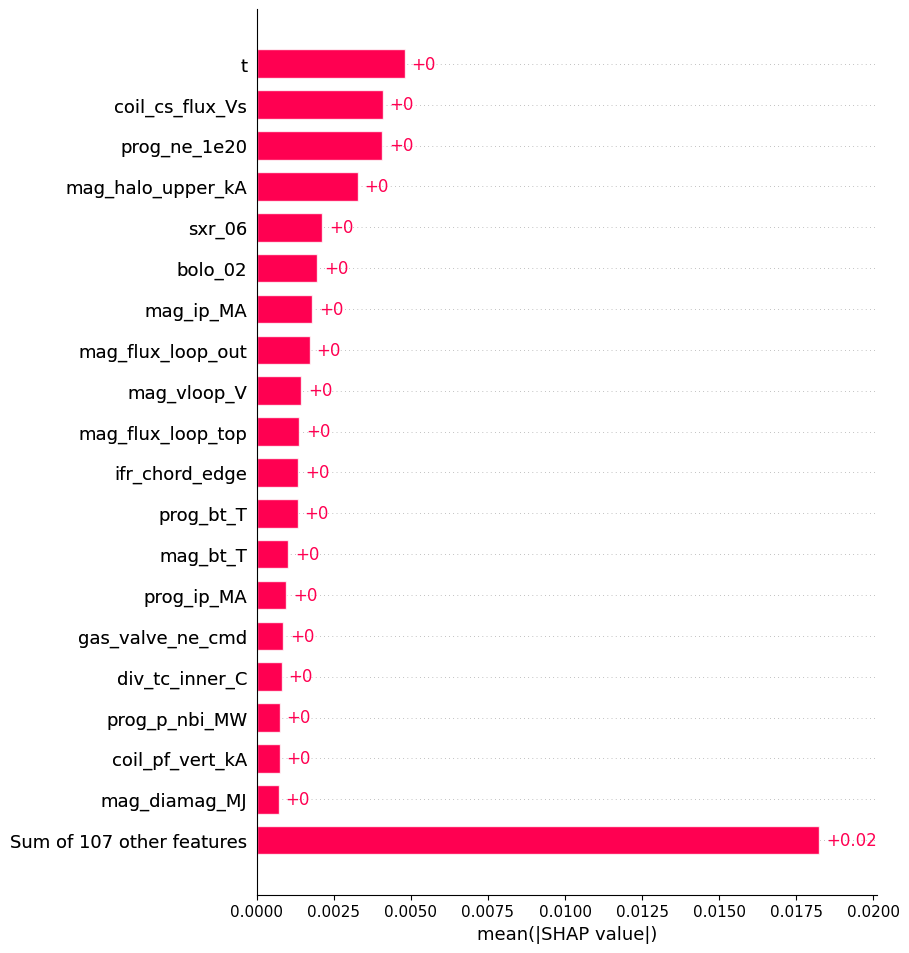

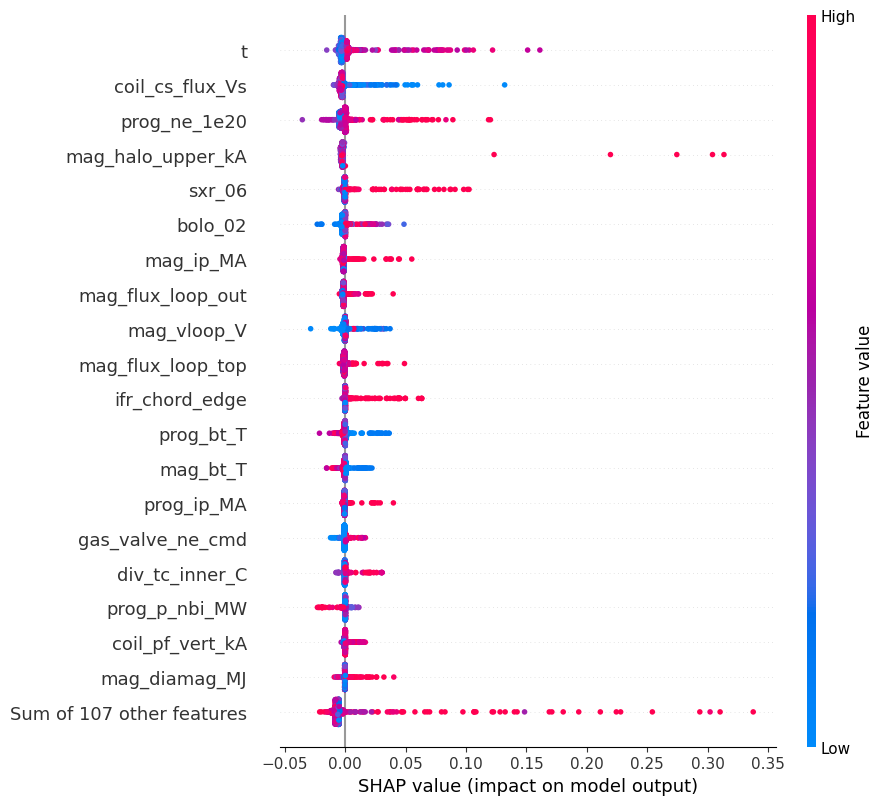

Максимальная оценка на выбранной подвыборке: 0.9801878333091736


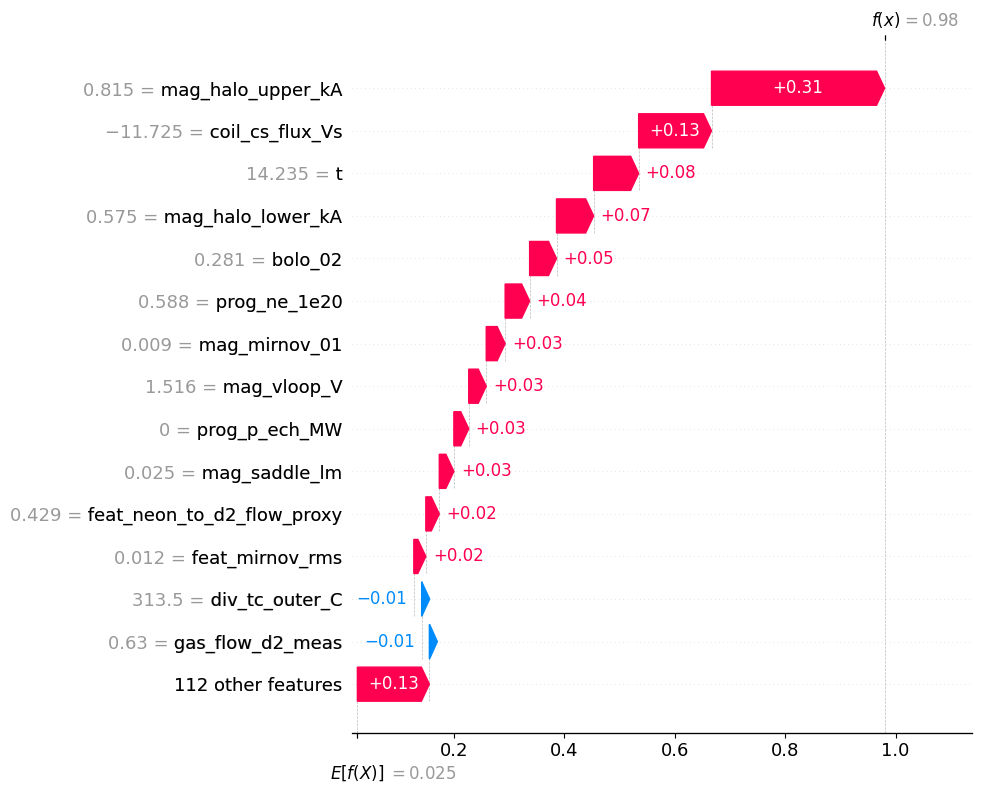

In [18]:

import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

# Воспроизводимый выбор уже обученного на train классификатора.
# В текущей v2 таблице лучший вариант по Caught — Physics.
variant = str(best_variant)

model_shap = fitted_models[variant]
columns = feature_columns_used[variant]

# Проверочные данные не использовались при обучении этого экземпляра модели.
X_valid_shap = feature_sets[variant].loc[
    valid_mask, columns
].copy()

X_train_shap = feature_sets[variant].loc[
    train_mask, columns
].copy()

# Ограничиваем вычислительную нагрузку.
rng = np.random.default_rng(42)

if len(X_valid_shap) > 1500:
    chosen = rng.choice(
        len(X_valid_shap), size=1500, replace=False
    )
    X_explain = X_valid_shap.iloc[chosen].copy()
else:
    X_explain = X_valid_shap.copy()

background_size = min(100, len(X_train_shap))
background = X_train_shap.sample(
    n=background_size, random_state=42
)

print("Вариант:", variant)
print("Проверочных строк для SHAP:", len(X_explain))
print("Признаков:", len(columns))

# Для XGBoost считаем вклады в вероятность положительного класса.
# Если версия SHAP не поддерживает такой режим,
# используем стандартный TreeExplainer и его шкалу вывода модели.
try:
    explainer = shap.TreeExplainer(
        model_shap,
        data=background,
        feature_perturbation="interventional",
        model_output="probability",
    )
    shap_values = explainer(X_explain)

    shap_scale = "probability"

except Exception as exc:
    print("Режим probability недоступен:", str(exc)[:250])
    print("Используется стандартная шкала TreeExplainer.")

    explainer = shap.TreeExplainer(model_shap)
    shap_values = explainer(X_explain)

    shap_scale = "model output"

# Глобальная важность: среднее абсолютное значение SHAP.
values = np.asarray(shap_values.values)

if values.ndim != 2:
    raise ValueError(
        f"Неожиданная форма SHAP values: {values.shape}. "
        "Проверь версию SHAP и формат результата классификатора."
    )

shap_importance = pd.DataFrame({
    "feature": columns,
    "mean_abs_shap": np.abs(values).mean(axis=0),
}).sort_values("mean_abs_shap", ascending=False)

print("Шкала SHAP:", shap_scale)
display(shap_importance.head(25))

# 1. Глобальное ранжирование признаков.
shap.plots.bar(shap_values, max_display=20)

# 2. Направление и разброс влияния признаков по проверочным точкам.
shap.plots.beeswarm(shap_values, max_display=20)

# 3. Локальное объяснение точки с максимальным предсказанным риском
# среди строк, выбранных для объяснения.
p_explain = model_shap.predict_proba(X_explain)[:, 1]
local_idx = int(np.argmax(p_explain))

print(
    "Максимальная оценка на выбранной подвыборке:",
    float(p_explain[local_idx])
)

shap.plots.waterfall(
    shap_values[local_idx],
    max_display=15,
)
